Con diferencias finitas centrales:
\begin{align*}
    \frac{d^2 y}{dx^2} = \frac{y_{i+1} - 2y_i + y_{i-1}}{(\Delta x)^2} \quad y \quad \frac{dy}{dx} = \frac{y_{i+1} - y_{i-1}}{2\Delta x}
\end{align*}
Con $y(x)=T(r)$.
\begin{align*}
    \frac{y_{i+1} - 2y_i + y_{i-1}}{(\Delta x)^2} + \frac{2}{r} \frac{y_{i+1} - y_{i-1}}{2\Delta x} &= 0 \\[10pt]
    \frac{y_{i+1} - 2y_i + y_{i-1}}{\Delta x} + \frac{1}{r}(y_{i+1} - y_{i-1}) &= 0 \\[10pt]
    \left(\frac{1}{\Delta x } + \frac{1}{r}\right) y_{i+1} - \frac{2}{\Delta x} y_i + \left(\frac{1}{\Delta x} - \frac{1}{r}\right) y_{i-1} &= 0
\end{align*}

**Comparación de errores absolutos:**

|   $N$ |   $\epsilon_{rel}$ ($\%$) |
|------:|--------------------------:|
|    10 |               8.55808e-14 |
|    50 |               7.28325e-13 |
|   100 |               1.24678e-12 |

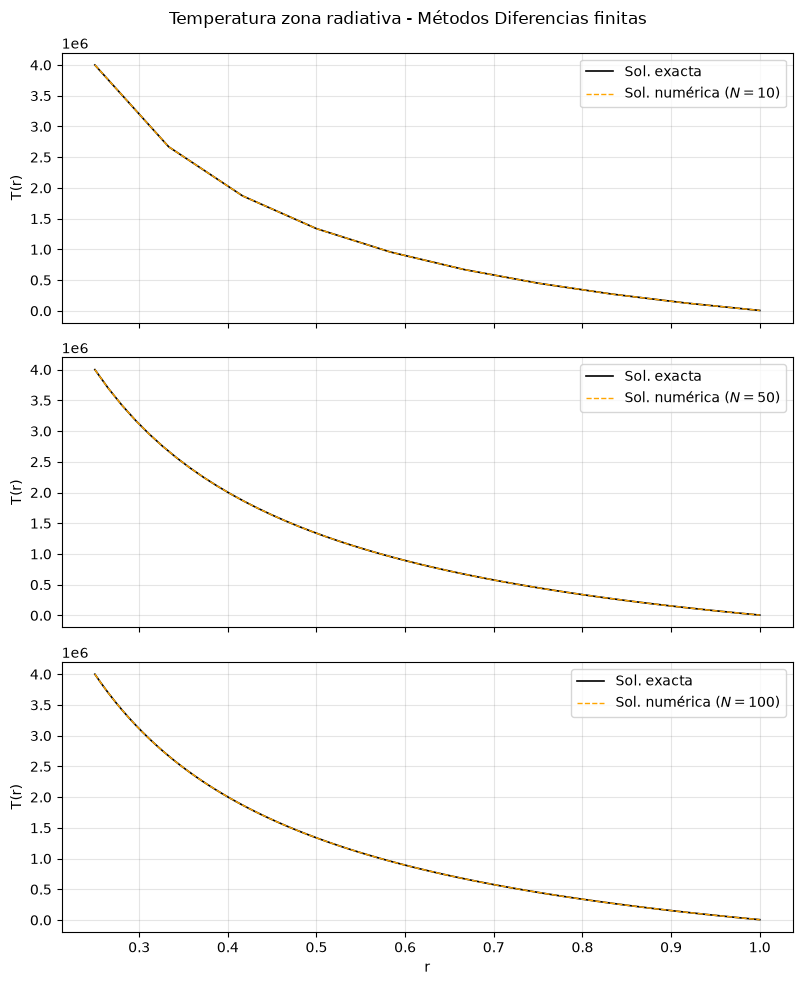

In [64]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

# PARÁMETROS:

R_sun  = 6.957e8 # m
Ti, Tf = 4e6, 5778 # K
N_arr  = [10, 50, 100]
xi, xf = 0.25, 1.0

def finite_diff(xi, xf, yi, yf, N):
    x = np.linspace(xi, xf, N)
    A = np.zeros((N, N))
    dx = (xf - xi)/(N-1)

    g = np.zeros(N)

    # Frontera:
    A[0, 0]   = 1; g[0]  = yi
    A[-1, -1] = 1; g[-1] = yf
    
    for i in range(1, N - 1):
        A[i, i-1] = (1/dx - 1/x[i])
        A[i, i] = -2/dx
        A[i, i+1] = (1/dx + 1/x[i])

        g[i] = 0

    return x, np.linalg.solve(A, g)

# Sol exacta:
def T_exact(r, xi, xf, Ti, Tf):
    A = (Ti - Tf)/(1/xi - 1/xf)
    B = Tf - A/xf 
    return B + A/r   


fig, axes = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

df = []
for i, N in enumerate(N_arr):
    ax = axes[i]

    x, y = finite_diff(xi, xf, Ti, Tf, N)
    y_exac = T_exact(x, xi, xf, Ti, Tf)

    err_abs = abs((y - y_exac)/y_exac) * 100
    eps_max = err_abs.max()

    df.append({
        r'$N$': N,
        r'$\epsilon_{rel}$ ($\%$)': eps_max,
    })

    ax.plot(x, y_exac, lw=1.2, ls='-', color='k', label='Sol. exacta')
    ax.plot(x, y, lw=1, ls='--', color='orange', label=rf'Sol. numérica ($N={N}$)')

    ax.grid(alpha=0.2, color='gray')
    ax.set(ylabel='T(r)')
    ax.set(xlabel='r' if i==2 else None)
    ax.legend()

df = '**Comparación de errores absolutos:**\n\n' + pd.DataFrame(df).to_markdown(index=False)
display(Markdown(df))

fig.suptitle('Temperatura zona radiativa - Métodos Diferencias finitas')
plt.tight_layout()
plt.show()

In [68]:
# Para valores de N menores a 10
N_arr = [3, 5, 7, 9]

df = []
for i, N in enumerate(N_arr):
    x, y = finite_diff(xi, xf, Ti, Tf, N)
    y_exac = T_exact(x, xi, xf, Ti, Tf)

    err_abs = abs((y - y_exac)/y_exac) * 100
    eps_max = err_abs.max()

    df.append({
        r'$N$': N,
        r'$\epsilon_{rel}$ ($\%$)': eps_max,
    })

df = '**Comparación de errores absolutos para N < 10:**\n\n' + pd.DataFrame(df).to_markdown(index=False)
display(Markdown(df))

**Comparación de errores absolutos para N < 10:**

|   $N$ |   $\epsilon_{rel}$ ($\%$) |
|------:|--------------------------:|
|     3 |               2.89366e-14 |
|     5 |               5.57855e-14 |
|     7 |               1.18804e-13 |
|     9 |               8.11201e-14 |

En este caso, se observa que la ecuación diferencial es exactamente igual a la aproximación por diferencias finitas, siendo el error únicamente numérico por redondeo.